# Classificador de Arestas usando Regressão Logística

## 9. Rotulacao fraca de arestas (treino) - Passo 1

Para cada sentenca dos casos de **treino**, gera os pares candidatos `(E1, E2)` + o texto intermediario (`span_between`) e atribui o rotulo fraco da aresta (`FAMILIAR_HISTORY`, `HISTORY`, `DIAGNOSED_WITH`, `PRESENTS_WITH`, `TAKES`, `UNDERWENT_EXAM`, `LOCATED_IN`, `REVEALS`, `HAS_EFFECT` ou `NONE`).

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from models.classificar_arestas.step1_weak_edges import (
    label_edges_dataframe,
    save_weak_edges,
    summarize_edges,
)

WEAK_EDGES_DIR = PROJECT_DIR / 'data' / 'processed' / 'weak_edges'

# 1) Gera pares candidatos (E1, E2) por sentenca no treino e rotula fracamente
edge_records_train = label_edges_dataframe(
    train,
    records,
    text_col=TEXT_COL,
    id_col='case_id',
    group_col=GROUP_COL,
)

# 2) Salva weak_edges.jsonl e exibe resumo
weak_edges_path = save_weak_edges(edge_records_train, WEAK_EDGES_DIR)
print('salvo em', weak_edges_path.relative_to(ROOT))
print()
summarize_edges(edge_records_train)

# 3) Visualiza exemplos de pares candidatos gerados no treino
df_edges_preview = pd.DataFrame(edge_records_train)[
    [
        'case_id',
        'e1_text',
        'type_E1',
        'span_between',
        'e2_text',
        'type_E2',
        'token_dist',
        'label',
    ]
]
display(df_edges_preview[df_edges_preview['label'] != 'NONE'].head(15))
display(df_edges_preview[df_edges_preview['label'] == 'NONE'].head(10))

salvo em data/processed/weak_edges/weak_edges.jsonl

Casos com pares: 45 | Total de pares candidatos: 2039
Arestas positivas: 786 (38.5%) | NONE (sem relacao): 1253 (61.5%)
Pares por rotulo de aresta: {'NONE': 1253, 'DIAGNOSED_WITH': 210, 'UNDERWENT_EXAM': 208, 'TAKES': 139, 'PRESENTS_WITH': 104, 'LOCATED_IN': 79, 'HISTORY': 33, 'REVEALS': 7, 'FAMILIAR_HISTORY': 6}
Arestas positivas por par de tipos: {'Patient->Disease': 249, 'Patient->Exam': 208, 'Patient->Medication': 139, 'Patient->Symptom': 104, 'Disease->Anatomy': 55, 'Symptom->Anatomy': 24, 'Exam->Result': 7}


,case_id,e1_text,type_E1,span_between,e2_text,type_E2,token_dist,label
1,PMC9387390_01,Patient,Patient,Computed,tomography,Exam,1,UNDERWENT_EXAM
2,PMC9387390_01,Patient,Patient,Computed tomography CT imaging showed nonspeci...,edema,Symptom,7,PRESENTS_WITH
4,PMC9387390_01,Patient,Patient,An upper gastrointestinal UGI contrast study and,barium enema,Exam,7,UNDERWENT_EXAM
8,PMC9387390_01,patient,Patient,underwent CT guided,biopsy,Exam,3,UNDERWENT_EXAM
9,PMC9387390_01,patient,Patient,underwent CT guided biopsy of the mass this wa...,adenocarcinoma,Disease,16,DIAGNOSED_WITH
12,PMC9387390_01,adenocarcinoma,Disease,thought to have arisen from the,upper gastrointestinal tract,Anatomy,6,LOCATED_IN
13,PMC9387390_01,Patient,Patient,Approximately 11 months after the initiation o...,nausea,Symptom,14,PRESENTS_WITH
14,PMC9387390_01,Patient,Patient,His imaging was consistent with gastroduodenal...,pancreatic,Disease,11,DIAGNOSED_WITH
15,PMC9387390_01,Patient,Patient,Sutures placed at the GJ were noted to be loos...,abscesses,Disease,14,DIAGNOSED_WITH
18,PMC9387390_01,Patient,Patient,The efferent limb was subsequently,intubated,Exam,5,UNDERWENT_EXAM


,case_id,e1_text,type_E1,span_between,e2_text,type_E2,token_dist,label
0,PMC9387390_01,man,Patient,with no significant past medical or surgical h...,diarrhea,Symptom,15,NONE
3,PMC9387390_01,tomography,Exam,CT imaging showed nonspecific mesenteric,edema,Symptom,5,NONE
5,PMC9387390_01,abdomen,Anatomy,demonstrated a central mesenteric mass abuttin...,pancreas,Anatomy,7,NONE
6,PMC9387390_01,abdomen,Anatomy,demonstrated a central mesenteric mass abuttin...,duodenum,Anatomy,22,NONE
7,PMC9387390_01,pancreas,Anatomy,encasing the superior mesenteric vessels causi...,duodenum,Anatomy,14,NONE
10,PMC9387390_01,biopsy,Exam,of the mass this was consistent with invasive ...,adenocarcinoma,Disease,12,NONE
11,PMC9387390_01,biopsy,Exam,of the mass this was consistent with invasive ...,upper gastrointestinal tract,Anatomy,19,NONE
16,PMC9387390_01,duodenum,Anatomy,and proximal,jejunum,Anatomy,2,NONE
17,PMC9387390_01,stomach,Anatomy,and proximal,small intestine,Anatomy,2,NONE
21,PMC3437073_01,immobile,Exam,and attached to the,skin,Anatomy,4,NONE


## 10. Modelo de Arestas: PMI + TF-IDF (texto intermediario) + Distancia + Regressao Logistica Multinomial

Para cada par candidato `(E1, E2)` na mesma sentenca, construimos um vetor numerico combinando:
- **Tipos das entidades:** `type_E1`, `type_E2`, `pair=type_E1->type_E2` e `reading_order`
- **N-gramas / TF-IDF do texto entre elas (`span_between`)** e da janela de contexto local
- **Metrica PMI (Pointwise Mutual Information):** $\text{PMI}(E_1, E_2) = \log_2 \frac{P(E_1, E_2)}{P(E_1)P(E_2)}$
- **Distancia:** `token_dist` (numero de palavras entre $E_1$ e $E_2$), `log_dist` e barreira de oracao.

No treino, aplicamos `CUE_DROPOUT = 0.5` (esconde palavras-gatilho em 50% das vezes) para que o modelo aprenda tambem pelo contexto, distancia e PMI.

In [ ]:
from project02.models.classificar_arestas.edge_features import (
    build_edge_dataset,
    make_edge_model,
)
from sklearn.metrics import classification_report
from sklearn.model_selection import GroupKFold

CUE_DROPOUT = 0.5

# Tres visoes do MESMO conjunto de pares candidatos de treino:
# 1) X_edge_tr: com dropout de pistas (treino)
# 2) X_edge_com: com todas as palavras visiveis (como na predicao)
# 3) X_edge_sem: sem as palavras-gatilho explicitas (mede generalizacao por TF-IDF residual, PMI, tipos e distancia)
X_edge_tr, y_edge, edge_ids = build_edge_dataset(
    edge_records_train, cue_dropout=CUE_DROPOUT, seed=SEED
)
X_edge_com, _, _ = build_edge_dataset(
    edge_records_train, cue_dropout=0.0, seed=SEED
)
X_edge_sem, _, _ = build_edge_dataset(
    edge_records_train, cue_dropout=1.0, seed=SEED
)

grupos_edge = np.array([artigo[cid] for cid, _ in edge_ids])
print(
    f'pares de treino: {len(y_edge)} | artigos: {len(set(grupos_edge))}'
)

n_splits_edge = min(N_FOLDS, len(set(grupos_edge)))
pred_edge_com = np.empty(len(y_edge), dtype=object)
pred_edge_sem = np.empty(len(y_edge), dtype=object)

for tr_idx, va_idx in GroupKFold(n_splits=n_splits_edge).split(
    np.zeros(len(y_edge)), y_edge, grupos_edge
):
  m_edge = make_edge_model(seed=SEED).fit(
      [X_edge_tr[k] for k in tr_idx], y_edge[tr_idx]
  )
  pred_edge_com[va_idx] = m_edge.predict([X_edge_com[k] for k in va_idx])
  pred_edge_sem[va_idx] = m_edge.predict([X_edge_sem[k] for k in va_idx])

print('=== ARESTAS COM pistas completas (como na predicao) ===')
print(classification_report(y_edge, pred_edge_com, zero_division=0))
print(
    '=== ARESTAS SEM pistas explicitas (generalizacao: PMI + TF-IDF contexto +'
    ' distancia + tipos) ==='
)
print(classification_report(y_edge, pred_edge_sem, zero_division=0))

pares de treino: 2039 | artigos: 40
=== ARESTAS COM pistas completas (como na predicao) ===
                  precision    recall  f1-score   support

  DIAGNOSED_WITH       0.96      0.96      0.96       210
FAMILIAR_HISTORY       0.33      0.17      0.22         6
         HISTORY       0.70      0.94      0.81        33
      LOCATED_IN       0.69      1.00      0.82        79
            NONE       1.00      0.93      0.96      1253
   PRESENTS_WITH       0.83      1.00      0.91       104
         REVEALS       0.64      1.00      0.78         7
           TAKES       0.96      0.99      0.97       139
  UNDERWENT_EXAM       0.92      1.00      0.96       208

        accuracy                           0.95      2039
       macro avg       0.78      0.89      0.82      2039
    weighted avg       0.95      0.95      0.95      2039

=== ARESTAS SEM pistas explicitas (generalizacao: PMI + TF-IDF contexto + distancia + tipos) ===
                  precision    recall  f1-score   supp

In [ ]:
# Treina o modelo final de arestas com todo o conjunto de treino e salva em disco
edge_model = make_edge_model(seed=SEED).fit(X_edge_tr, y_edge)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(edge_model, MODEL_DIR / 'edge_model.joblib')
print('modelo de arestas salvo em', (MODEL_DIR / 'edge_model.joblib').relative_to(ROOT))
print()

# O que a Regressao Logistica Multinomial aprendeu: features de maior peso em cada classe de aresta
vec_e, clf_e = edge_model.steps[0][1], edge_model.steps[1][1]
nomes_e = vec_e.get_feature_names_out()
for k, classe in enumerate(clf_e.classes_):
    top = nomes_e[np.argsort(clf_e.coef_[k])[-8:][::-1]]
    print(f'{classe:18}', ', '.join(top))

modelo de arestas salvo em data/processed/model/edge_model.joblib

DIAGNOSED_WITH     pair_clause=Patient->Disease|same=True, pair=Patient->Disease, type_E2=Disease, pair_ppmi=Patient->Disease, pair_order=Patient->Disease|E1_before_E2, ctx_tfidf:the, pair_cue=Patient->Disease|DIAGNOSED, ctx_tfidf:the and
FAMILIAR_HISTORY   head_E2=epilepsy, pair_cue=Patient->Disease|FAMILY, cue=FAMILY, span_tfidf:family, head_E2=syndrome, span_tfidf:was negative, head_E2=conjunction, span_tfidf:negative
HISTORY            pair_cue=Patient->Disease|HISTORY, cue=HISTORY, head_E1=female, head_E2=insufficiency, span_tfidf:underlying, head_E2=fibrillation, head_E2=reflux, head_E2=ulceration
LOCATED_IN         pair_ppmi=Symptom->Anatomy, pair_ppmi=Disease->Anatomy, type_E2=Anatomy, cue=LOCATED, pair_dist=Symptom->Anatomy|close_1_3, pair_dist=Disease->Anatomy|med_4_8, pair_clause=Disease->Anatomy|same=True, pair=Disease->Anatomy
NONE               cue=NEGATION, span_tfidf:no, pair_cue=Patient->Disease|NEGATIO

In [ ]:
from project02.models.classificar_arestas.edge_features import (
    predict_case_edges,
)

arestas_teste = []
todos_pares_teste = []

for row, ents in zip(test.to_dict('records'), test['entities']):
    cid = str(row['case_id'])
    aid = str(row[GROUP_COL])
    txt = str(row[TEXT_COL])

    # Todos os pares candidatos com distribuicao de probabilidades Softmax
    pares_all = predict_case_edges(edge_model, cid, aid, txt, ents, only_positive=False)
    todos_pares_teste.extend(pares_all)

    # Apenas as arestas positivas (pred_label != 'NONE') para construir o Grafo de Conhecimento
    arestas_pos = [
        {
            'e1_text': r['e1_text'],
            'type_E1': r['type_E1'],
            'edge_label': r['pred_label'],
            'e2_text': r['e2_text'],
            'type_E2': r['type_E2'],
            'span_between': r['span_between'],
            'token_dist': r['token_dist'],
            'pmi_head': r['pmi_head'],
            'confidence': r['pred_confidence'],
            'probabilities': r['probabilities'],
        }
        for r in pares_all if r['pred_label'] != 'NONE'
    ]
    arestas_teste.append(arestas_pos)

test['edges'] = arestas_teste
print('casos de teste processados:', len(test))
print('total de arestas extraidas no teste:', sum(len(x) for x in arestas_teste))
print('arestas predita por tipo:', pd.Series([
    e['edge_label'] for lista in arestas_teste for e in lista
]).value_counts().to_dict())

# Exibe a tabela de probabilidades Softmax para os pares do primeiro caso de teste (estilo Box 3)
df_box3 = pd.DataFrame([r for r in todos_pares_teste if r['case_id'] == str(test.iloc[0]['case_id'])])
if len(df_box3):
    cols_show = ['e1_text', 'type_E1', 'span_between', 'e2_text', 'type_E2', 'token_dist', 'pmi_head', 'pred_label', 'pred_confidence', 'probabilities']
    display(df_box3[cols_show].head(15))

casos de teste processados: 11
total de arestas extraidas no teste: 224
arestas predita por tipo: {'UNDERWENT_EXAM': 71, 'DIAGNOSED_WITH': 61, 'TAKES': 30, 'LOCATED_IN': 23, 'PRESENTS_WITH': 22, 'HISTORY': 10, 'REVEALS': 6, 'FAMILIAR_HISTORY': 1}


,e1_text,type_E1,span_between,e2_text,type_E2,token_dist,pmi_head,pred_label,pred_confidence,probabilities
0,woman,Patient,presented with a 3-day history of right flank ...,abdominal pain,Symptom,11,1.319,PRESENTS_WITH,0.9832,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
1,woman,Patient,presented with a 3-day history of right flank ...,nausea,Symptom,15,3.695,PRESENTS_WITH,0.9869,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
2,woman,Patient,presented with a 3-day history of right flank ...,constipation,Symptom,17,8.087,PRESENTS_WITH,0.9851,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
3,abdominal pain,Symptom,associated with,nausea,Symptom,2,3.514,NONE,0.9526,"{'DIAGNOSED_WITH': 0.0031, 'FAMILIAR_HISTORY':..."
4,abdominal pain,Symptom,associated with nausea and,constipation,Symptom,4,6.322,NONE,0.9999,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
5,nausea,Symptom,and,constipation,Symptom,1,7.746,NONE,0.9995,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
6,Patient,Patient,Her past medical family and medication history...,physical examination,Exam,12,1.299,UNDERWENT_EXAM,0.7049,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."
7,Patient,Patient,She underwent contrast enhanced computed,tomography,Exam,5,1.089,UNDERWENT_EXAM,0.9841,"{'DIAGNOSED_WITH': 0.0005, 'FAMILIAR_HISTORY':..."
8,tomography,Exam,demonstrating a 6cm cystic lesion between the,stomach,Anatomy,7,4.097,NONE,0.9920,"{'DIAGNOSED_WITH': 0.0008, 'FAMILIAR_HISTORY':..."
9,tomography,Exam,demonstrating a 6cm cystic lesion between the ...,pancreas,Anatomy,13,5.075,NONE,0.9997,"{'DIAGNOSED_WITH': 0.0, 'FAMILIAR_HISTORY': 0...."


## Edge Metrics

=== RESUMO GLOBAL (APENAS ARESTAS POSITIVAS DO GRAFO) ===


conjunto,Treino CV (com pistas),Treino CV (sem pistas),Teste (com pistas),Teste (sem pistas)
n_pares,2039.000,2039.000,439.000,439.000
precision,0.879,0.799,0.905,0.785
recall,0.977,0.949,0.972,0.955
f1,0.925,0.867,0.937,0.862



=== METRICAS POR TIPO DE ARESTA (TREINO CV vs TESTE) ===


precision                                    recall                                        f1                                   support                       
conjunto         Teste (com pistas) Treino CV (com pistas) Teste (com pistas) Treino CV (com pistas) Teste (com pistas) Treino CV (com pistas) Teste (com pistas) Treino CV (com pistas)
classe                                                                                                                                                                                  
DIAGNOSED_WITH                0.964                  0.962              0.947                  0.962              0.956                  0.962               57.0                  210.0
FAMILIAR_HISTORY              1.000                  0.333              1.000                  0.167              1.000                  0.222                1.0                    6.0
HISTORY                       0.857                  0.705              1.000                  0.939              0.923                  0.805                6.0                   33.0
LOCATED_IN                    0.722                  0.693              0.929                  1.000              0.812                  0.819               14.0                   79.0
NONE                          0.980                  0.997              0.932                  0.927              0.955                  0.960              263.0                 1253.0
PRESENTS_WITH                 0.864                  0.832              1.000                  1.000              0.927                  0.908               19.0                  104.0
REVEALS                       0.667                  0.636              1.000                  1.000              0.800                  0.778                2.0                    7.0
TAKES                         0.905                  0.958              1.000                  0.986              0.950                  0.972               19.0                  139.0
UNDERWENT_EXAM                0.934                  0.924              0.983                  0.995              0.958                  0.958               58.0                  208.0

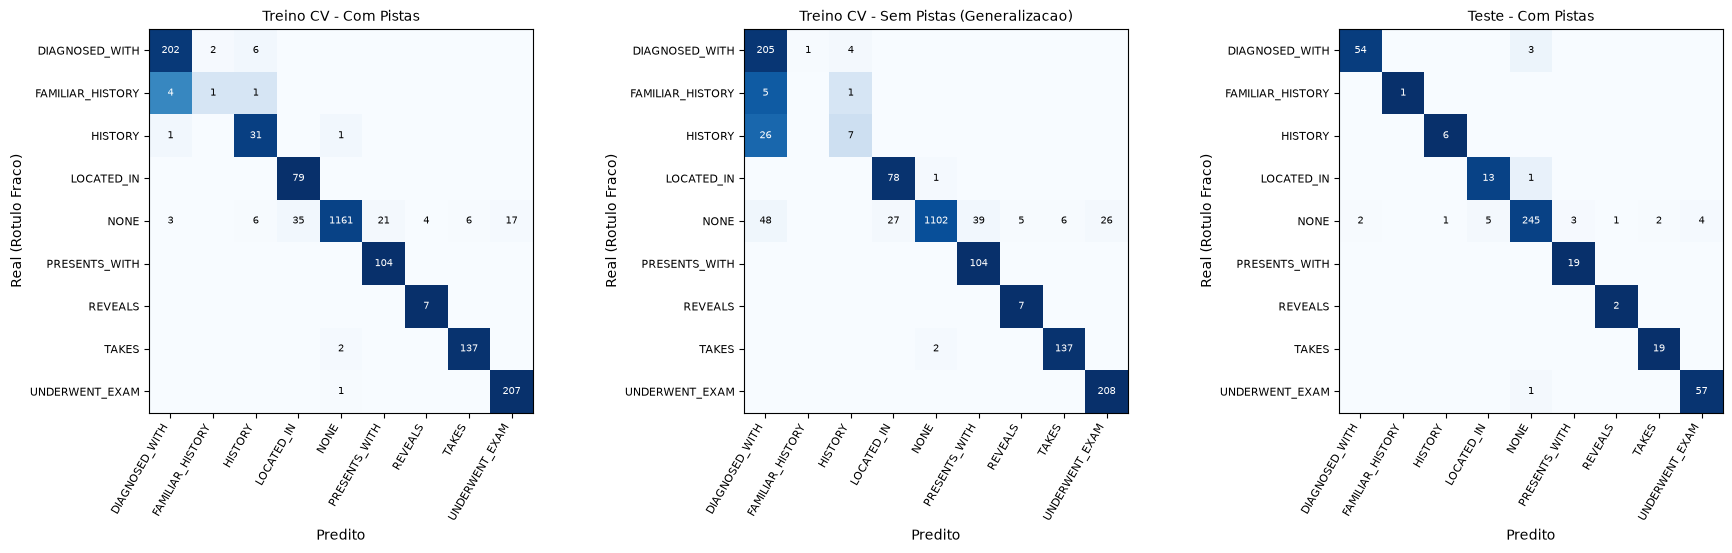

In [ ]:
# =====================================================================
# 10.1 METRICAS ESSENCIAIS DO CLASSIFICADOR DE ARESTAS (TREINO e TESTE)
# =====================================================================
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import GroupKFold

from project02.models.classificar_nos.step2_weak_labels import label_dataframe

NEG = 'NONE'


def edge_metrics_clean(y_true, y_pred, classes=None, name=''):
    """
    Calcula apenas as metricas essenciais para construcao do grafo (ignorando NONE nas medias):
      - Micro (sobre as arestas positivas): avalia a qualidade global das arestas extraidas no grafo.
      - Macro (sobre as arestas positivas): avalia o equilibrio entre os tipos de aresta (raras vs frequentes).
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    classes = list(classes) if classes is not None else sorted(set(y_true) | set(y_pred))
    pos_classes = [c for c in classes if c != NEG]

    p_mic, r_mic, f1_mic, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=pos_classes, average='micro', zero_division=0
    )
    

    resumo = {
        'conjunto': name,
        'n_pares': int(len(y_true)),
        'precision': p_mic,
        'recall': r_mic,
        'f1': f1_mic,
    }

    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=classes, average=None, zero_division=0
    )
    por_classe = pd.DataFrame({
        'conjunto': name,
        'classe': classes,
        'precision': p,
        'recall': r,
        'f1': f,
        'support': s,
    })
    return resumo, por_classe


def plot_confusion(y_true, y_pred, classes, title, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax = ax or plt.gca()
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=60, ha='right', fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j]:
                ax.text(
                    j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cmn[i, j] > 0.5 else 'black',
                )
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real (Rotulo Fraco)')
    ax.set_title(title, fontsize=10)


# ---------------------------------------------------------------------
# A) VALIDACAO CRUZADA NO TREINO (POR ARTIGO)
# ---------------------------------------------------------------------
classes_edge = list(edge_model.classes_)
y_edge = np.asarray(y_edge)

pred_cv_com = np.empty(len(y_edge), dtype=object)
pred_cv_sem = np.empty(len(y_edge), dtype=object)

for tr_idx, va_idx in GroupKFold(n_splits=n_splits_edge).split(np.zeros(len(y_edge)), y_edge, grupos_edge):
    m_fold = make_edge_model(seed=SEED).fit([X_edge_tr[k] for k in tr_idx], y_edge[tr_idx])
    pred_cv_com[va_idx] = m_fold.predict([X_edge_com[k] for k in va_idx])
    pred_cv_sem[va_idx] = m_fold.predict([X_edge_sem[k] for k in va_idx])

resumos, por_classe = [], []
for nome, pred in [
    ('Treino CV (com pistas)', pred_cv_com),
    ('Treino CV (sem pistas)', pred_cv_sem),
]:
    r, pc = edge_metrics_clean(y_edge, pred, classes_edge, nome)
    resumos.append(r)
    por_classe.append(pc)

# ---------------------------------------------------------------------
# B) AVALIACAO NO TESTE
# ---------------------------------------------------------------------
records_test, _, _ = label_dataframe(
    test, dic, text_col=TEXT_COL, id_col='case_id', group_col=GROUP_COL
)
edge_records_test = label_edges_dataframe(
    test, records_test, text_col=TEXT_COL, id_col='case_id', group_col=GROUP_COL
)

X_te_com, y_te, _ = build_edge_dataset(edge_records_test, cue_dropout=0.0, seed=SEED)
X_te_sem, _, _ = build_edge_dataset(edge_records_test, cue_dropout=1.0, seed=SEED)
y_te = np.asarray(y_te)

pred_te_com = edge_model.predict(X_te_com)
pred_te_sem = edge_model.predict(X_te_sem)

for nome, pred in [
    ('Teste (com pistas)', pred_te_com),
    ('Teste (sem pistas)', pred_te_sem),
]:
    r, pc = edge_metrics_clean(y_te, pred, classes_edge, nome)
    resumos.append(r)
    por_classe.append(pc)

# ---------------------------------------------------------------------
# C) EXIBICAO DOS RESULTADOS E MATRIZES DE CONFUSAO
# ---------------------------------------------------------------------
df_resumo = pd.DataFrame(resumos).set_index('conjunto')
df_por_classe = pd.concat(por_classe, ignore_index=True)

print('=== RESUMO GLOBAL (APENAS ARESTAS POSITIVAS DO GRAFO) ===')
display(df_resumo.T.round(3))

print('\n=== METRICAS POR TIPO DE ARESTA (TREINO CV vs TESTE) ===')
display(
    df_por_classe[df_por_classe['conjunto'].isin(['Treino CV (com pistas)', 'Teste (com pistas)'])]
    .pivot(index='classe', columns='conjunto', values=['precision', 'recall', 'f1', 'support'])
    .round(3)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plot_confusion(y_edge, pred_cv_com, classes_edge, 'Treino CV - Com Pistas', axes[0])
plot_confusion(y_edge, pred_cv_sem, classes_edge, 'Treino CV - Sem Pistas (Generalizacao)', axes[1])
plot_confusion(y_te, pred_te_com, classes_edge, 'Teste - Com Pistas', axes[2])
plt.tight_layout()
plt.show()